<a href="https://colab.research.google.com/github/Traffict/Linear-Regression-Scratch/blob/master/1_Lineal_regression_Scratch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
from sklearn.datasets import fetch_california_housing

In [ ]:
california = fetch_california_housing()

In [ ]:
print(california.DESCR)

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib repository.
https://www.dcc.fc.up.pt/~ltorgo/Regression/cal_housing.html

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per ce

In [ ]:
# k = Tolerance of outliners
def mask_iqr(data, k=1.5):
    """ Return a boolean mask True = row no outliners"""
    # convert the array from row to column
    d2 = np.atleast_2d(data.T).T  # Transposed
    # get cuartiles to check the ouliners up and down
    q1 = np.percentile(d2, 25, axis=0) # get data from < 25%
    q3 = np.percentile(d2, 75, axis=0) # get data from > 75%
    # get the data in the middle no outliners
    iqr = q3 - q1

    # a limit for outliners
    limite_inf = q1 - k * iqr # lower limit
    limite_sup = q3 + k * iqr # uper limit

    # remove data out of allow range
    dentro = (d2 >= limite_inf) & (d2 <= limite_sup)

    return dentro.all(axis=1 )

In [ ]:
# we'll use average Rooms to predict the price of housing
# we get all data from the second column
X = california.data[:, 2]
# the price of housing
Y = california.target


In [ ]:
mask = mask_iqr(X)
mask &= (Y < 5.0)

In [ ]:
X = np.asarray(X, dtype=float)
Y = np.asarray(Y, dtype=float)


X = X[mask]
Y = Y[mask]

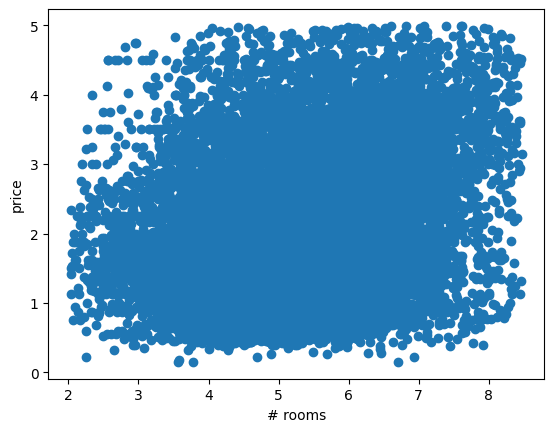

In [ ]:
# roms vs price
# price are reduce 2 = $200.000
plt.scatter(X, Y)
plt.xlabel('# rooms')
plt.ylabel('price')
plt.show()

# The formula that we need
# MCO

we need to multiply de parameter b in y = x*w + b by 1 to get a parameter and the ai uset it like a weight and not a independent value

beta igual a x traspuesta de x inversa por x traspuesta de y


$\beta = (X^{T}X)^{-1}X^{T}Y$

In [ ]:
# np.c_ pega arrays como columnas, lado a lado. Es un atajo para np.column_stack.
# X.shape[0] = 2054 rows
# X.shape[1] = 8 columns
X = np.c_[np.ones(X.shape[0]), X]

In [ ]:
# Transpose of x
# @ multpy matrix
# inversa = inv
B = np.linalg.inv(X.T @ X) @ X.T @ Y

In [ ]:
# X is the point in Y where X = 0 \
# Y is the slop, how higer is the angle of the line (every increase between points has a aument of Y)
B

array([0.73427505, 0.22850278])

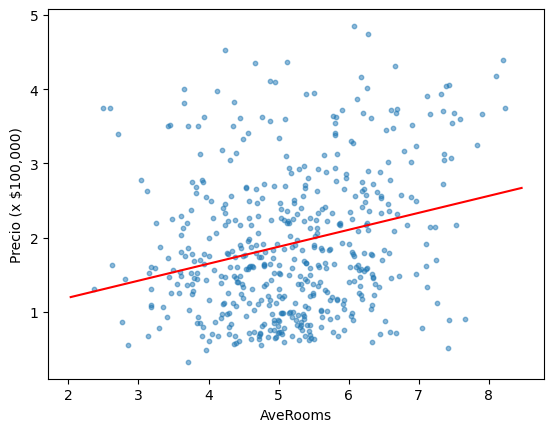

In [ ]:
rng = np.random.default_rng(42) # rng number selector
idx = rng.choice(X.shape[0], size=500, replace=False) # sleect 600 index to graph

x = X[:, 1] # real column and not one's column
# S = size
# alpha = trasnparent
plt.scatter(x[idx], Y[idx], s=10, alpha=0.5) # graph those points
plt.plot([x.min(), x.max()],
         [B[0] + B[1] * x.min(), B[0] + B[1] * x.max()],
         c='red')
plt.xlabel("AveRooms")
plt.ylabel("Precio (x $100,000)")
plt.show()